# <center><font color = "iceblue"> TRABALHO FINAL - A2 - ANÁLISE EXPLORATÓRIA DE DADOS E VISUALIZAÇÕES
## <center><font color = "blue:red"> O Cenário Nacional da Educação Especial no Brasil - Uma visão estístico-temporal entre 2015 e 2025

**Alunos: Ian Luca Marinho Aguiar / João Pedro Menezes Barros Dantas de Souza / Davi da Cunha Ribeiro <br>
Turma: 1708-OBG**

<p style="text-align: justify;"> Para mais informações sobre a proposta do trabalho, confira em "Proposta_Educacao_Brasil.pdf" no <a href="https://exemplo.com" class="meu-botao">github disponibilizado</a>
</br>
O presente arquivo consiste na resolução das 7 questões levantadas pela análise dos bancos de dados obtidos na etapa inicial do projeto, advindos do Censo Demográfico de 2022 e as Sinopses Estatísticas da Educação Básica de 2015 a 2025. As perguntas são:

<ol><b>
    <li>Como evoluíram as matrículas da educação especial entre 2015 e 2025, em comparação com o total da educação básica?
    <li>Como as matrículas se dividem entre deficiências, TEA e altas habilidades, e como essa composição mudou ao longo dos anos?
    <li>Em que etapas de ensino estão esses alunos, e a presença deles diminui ao longo da trajetória escolar?
    <li>Qual a parcela desses alunos em classes comuns, e como ela difere entre rede pública e privada?
    <li>O crescimento e a inclusão vistos no país se repetem em todas as regiões e estados, ou a média nacional é puxada por poucos estados?
    <li>Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?
    <li>Os estados onde a educação especial mais cresceu são os que mais ampliaram a inclusão em classes comuns?
<ol></b>

As fontes utilizadas para efetuar as visualizações podem ser obtidas a partir do <a href="https://exemplo.com" class="meu-botao">github disponibilizado</a>












</p>



# <font color="blue:red">-------------------------------------------------------------------------------------------
# <font color="iceblue"><p style="text-align: justify"><center>IMPORTAÇÕES</p>
# <font color="blue:red">-------------------------------------------------------------------------------------------

In [13]:
# Manipulação dos dados
import pandas as pd

# Visualizações
import plotly.express as px
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
from IPython.display import display


#Importações - Pergunta 1, 2 e 3
try:
    bd_25 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2025
    bd_20 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2020.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2020
    bd_15 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2015.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2015
    
    # É importante ressaltar que o banco de dados de 2020 (nomeado como 'bd_20') é de 08/03/2021, atualizado após as instabilidades conferidas
    # pela pandemia de COVID-19 que afetou o cenário educacional nacional.
    
    # Tabelas que serão utilizadas para responder às qeustões 1, 2 e 3
    tb_11_2025 = pd.read_excel(bd_25, sheet_name = "Educação Básica 1.1")
    tb_155_2025 = pd.read_excel(bd_25, sheet_name = "Educação Especial 1.55")
    tb_158_2025 = pd.read_excel(bd_25, sheet_name = "1.58") # No ano de 2025, a aba que contém as informações sobre alunos com diagnóstico
    # de superdotação e TEA's é nomeada de maneira distinta dos anos anteriores, como "1.58".
    
    tb_11_2020 = pd.read_excel(bd_20, sheet_name = "Educação Básica 1.1")
    tb_138_2020 = pd.read_excel(bd_20, sheet_name = "Educação Especial 1.38")
    tb_143_2020 = pd.read_excel(bd_20, sheet_name = "1.43")
    tb_149_2020 = pd.read_excel(bd_20, sheet_name = "1.49")

    
    tb_11_2015 = pd.read_excel(bd_15, sheet_name = "Educação Básica 1.1")
    tb_138_2015 = pd.read_excel(bd_15, sheet_name = "Educação Especial 1.38")
    tb_143_2015 = pd.read_excel(bd_15, sheet_name = "1.43")
    tb_149_2015 = pd.read_excel(bd_15, sheet_name = "1.49")
except FileNotFoundError:
    print("Algum dos arquivos para responder às perguntas 1,2 e 3 não foi encontrado!")

#Importações - Pergunta 4
try:
    caminho = pd.read_csv("pergunta4_dados_limpos_inep.csv")
except FileNotFoundError:
    print("O arquivo 'pergunta4_dados_limpos_inep.csv' não foi encontrado!")
#Importações - Pergunta 5
try:
    arquivo = pd.ExcelFile('base_limpa_pergunta5_inep_2015_2020_2025.xlsx')
    dados = pd.read_excel(arquivo, sheet_name='Base limpa', header=3)
except FileNotFoundError:
    print("O arquivo 'base_limpa_pergunta5_inep_2015_2020_2025.xlsx' não foi encontrado!")

#Importações - Pergunta 6
#Importações - Pergunta 7

O arquivo 'pergunta4_dados_limpos_inep.csv' não foi encontrado!
O arquivo 'base_limpa_pergunta5_inep_2015_2020_2025.xlsx' não foi encontrado!


## <font color = "iceblue"> PERGUNTA 1: <font color = "skyblue">Como evoluíram as matrículas da educação especial entre 2015 e 2025, em comparação com o total da educação básica?

,Região,Estado,Município,IBGE,2015,2020,2025
0,Brasil,<NA>,<NA>,<NA>,1.91,2.77,5.34
1,Norte,<NA>,<NA>,<NA>,1.57,2.56,5.13
2,Norte,Rondônia,<NA>,<NA>,2.34,3.18,6.09
3,Norte,Rondônia,Alta Floresta D'Oeste,1100015,2.49,2.14,4.79
4,Norte,Rondônia,Alto Alegre dos Parecis,1100379,2.79,2.58,4.99
...,...,...,...,...,...,...,...
5599,Centro-Oeste,Goiás,Vicentinópolis,5222054,2.65,2.10,4.61
5600,Centro-Oeste,Goiás,Vila Boa,5222203,2.04,1.91,4.07
5601,Centro-Oeste,Goiás,Vila Propício,5222302,2.88,3.40,8.99
5602,Centro-Oeste,Distrito Federal,<NA>,<NA>,2.45,2.64,4.78


,Ano,Percentual
0,Região,Brasil
1,Estado,<NA>
2,Município,<NA>
3,IBGE,<NA>
4,2015,1.91
5,2020,2.77
6,2025,5.34


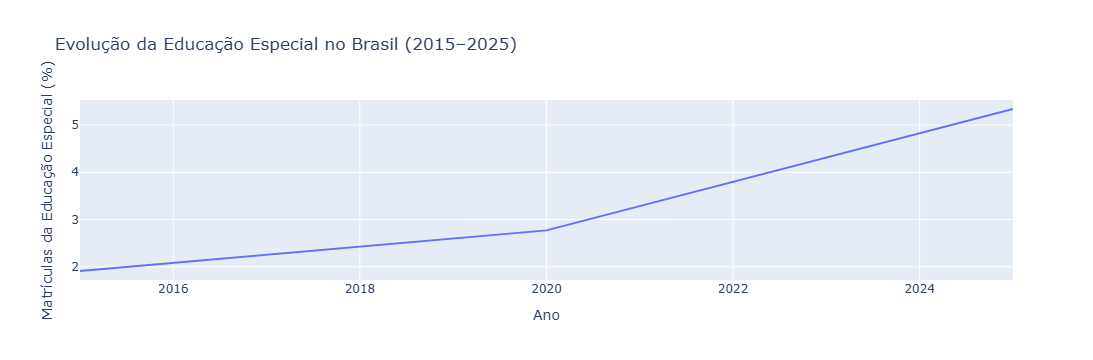

In [14]:
# Aqui, a resposta será dada por meio da porcentagem de matrículas de alunos especiais com relação às matrículas totais.
# A visualização será dada por meio uma série temporal com intervalos de 5 anos.

# Função para limpar a tabela e retirar as inconsistências que as células mescladas induzem na análise dos dados

#Este dicionário servirá para a organização dos próximos códigos
tabelas = {
    2015: (tb_11_2015, tb_138_2015),
    2020: (tb_11_2020, tb_138_2020),
    2025: (tb_11_2025, tb_155_2025)
}
def limpar(df):
    df = df.iloc[:, :5].copy()
    df.columns = ["Região", "Estado", "Município", "IBGE", "Total"]

    df["Total"] = pd.to_numeric(df["Total"], errors="coerce")
    df["IBGE"] = pd.to_numeric(df["IBGE"], errors="coerce").astype("Int64")
    df = df[df["Total"].notna()].copy()
    
    for coluna in ["Região", "Estado", "Município"]:
        df[coluna] = df[coluna].astype("string").str.strip().replace("", pd.NA)

    df["id"] = "REG:" + df["Região"]
    df.loc[df["Estado"].notna(), "id"] = "UF:" + df["Estado"]
    df.loc[df["IBGE"].notna(), "id"] = "MUN:" + df["IBGE"].astype("string")

    df = df.dropna(subset=["id"])
    return df.set_index("id")


# Monta a view a partir das localidades de 2025 (escolhemos utilizar os padrões de 2025 e não os de 2015 e 2020)
view = limpar(tb_11_2025)[["Região", "Estado", "Município", "IBGE"]].copy()

# Calcula os percentuais
for ano, (basica, especial) in tabelas.items():
    total = limpar(basica)["Total"]
    esp = limpar(especial)["Total"]

    view[ano] = (esp / total * 100).round(2)

view = view.reset_index(drop=True)

display(view)


# Projetando uma série temporal num plano bidimensional:

view_brasil = view.loc[view["Região"] == "Brasil"].melt(var_name="Ano", value_name = "Percentual")

display(view_brasil)

# Gráfico bidimensional
fig = px.line(view_brasil, x = "Ano", y = "Percentual", title = "Evolução da Educação Especial no Brasil (2015–2025)", 
              labels = {"Ano": "Ano", "Percentual": "Matrículas da Educação Especial (%)"})
fig.show()

## 1.x) Leitura dos resultados

## <font color = "iceblue"> PERGUNTA 2: <font color = "skyblue">Como as matrículas se dividem entre deficiências, TEA e altas habilidades, e como essa composição mudou ao longo dos anos?

## 2.x) Leitura dos resultados

## <font color = "iceblue"> PERGUNTA 3: <font color = "skyblue">Em que etapas de ensino estão esses alunos, e a presença deles diminui ao longo da trajetória escolar?

## 3.x) Leitura dos resultados

## <font color = "iceblue"> PERGUNTA 4: <font color = "skyblue">Qual a parcela desses alunos em classes comuns, e como ela difere entre rede pública e privada?

**Matrículas em classes comuns nas redes pública e privada** <br>
A comparação considera os anos de 2015, 2020 e 2025, com dados das Sinopses Estatísticas da Educação Básica do INEP.
A tabela reúne, para cada rede e ano, as matrículas em classes comuns e exclusivas. A rede pública inclui as dependências federal, estadual e municipal.

Em 2015 e 2020 foram usadas as tabelas 1.40 e 1.46 das Sinopses; em 2025, as tabelas 1.61 e 1.68.

In [15]:
# Cada linha do arquivo corresponde a uma rede em um dos três anos.
dados = pd.read_csv(caminho, encoding="utf-8-sig")
dados["total_matriculas"] = dados["classes_comuns"] + dados["classes_exclusivas"]

# Conferimos se as duas redes somam o total nacional informado pelo INEP.
totais_por_ano = dados.groupby("ano")["total_matriculas"].sum()
assert totais_por_ano.to_dict() == {2015: 930683, 2020: 1308900, 2025: 2458159}
assert len(dados) == 6 and not dados.duplicated(["ano", "rede"]).any()

display(dados.sort_values(["ano", "rede"]).reset_index(drop=True))

FileNotFoundError: [Errno 2] No such file or directory: 'pergunta4_dados_limpos_inep.csv'

## 4.1) Percentual em classes comuns

Para comparar as redes, dividimos as matrículas em classes comuns pelo total de matrículas da educação especial **dentro de cada rede**. Também calculamos a diferença entre os percentuais, em pontos percentuais.

In [ ]:
# Percentual de matrículas em classes comuns em cada rede.
dados["percentual_comuns"] = (
    dados["classes_comuns"] / dados["total_matriculas"] * 100
)

comparacao = dados.pivot(
    index="ano", columns="rede", values="percentual_comuns"
).sort_index()

comparacao["Diferença (p.p.)"] = comparacao["Pública"] - comparacao["Privada"]

display(comparacao.round(2))

## 4.2) Evolução por rede

O gráfico mostra o percentual de matrículas em classes comuns nas duas redes. Cada ponto corresponde a um ano disponível na base; as linhas apenas ligam esses valores.

In [ ]:
anos = [2015, 2020, 2025]
cores = {"Pública": "#176B78", "Privada": "#C76A32"}

figura, eixo = plt.subplots(figsize=(10, 5.6))

for rede in ["Pública", "Privada"]:
    dados_rede = dados[dados["rede"] == rede].sort_values("ano")

    eixo.plot(
        dados_rede["ano"], dados_rede["percentual_comuns"],
        marker="o", markersize=7, linewidth=2.5,
        color=cores[rede], label=f"Rede {rede.lower()}"
    )

    # Os valores ao lado dos pontos facilitam a leitura dos três anos.
    for _, linha in dados_rede.iterrows():
        deslocamento = -16 if rede == "Pública" else 10
        eixo.annotate(
            f'{linha["percentual_comuns"]:.1f}%'.replace(".", ","),
            (linha["ano"], linha["percentual_comuns"]),
            xytext=(0, deslocamento), textcoords="offset points",
            ha="center", fontsize=10, color=cores[rede]
        )

eixo.set_title("Matrículas em classes comuns, por rede de ensino", fontsize=13, pad=18)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Matrículas em classes comuns (%)")
eixo.set_xticks(anos)
eixo.set_xlim(2014, 2026)
eixo.set_ylim(0, 105)
eixo.set_yticks(range(0, 101, 20))
eixo.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
eixo.grid(axis="y", alpha=0.2)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(loc="upper left", frameon=False, ncol=2)

figura.text(
    0.12, 0.015,
    "Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).",
    fontsize=8.5, color="#555555"
)
figura.subplots_adjust(bottom=0.17, top=0.88)
plt.savefig("pergunta4_grafico_redes.png", dpi=180, bbox_inches="tight")
plt.show()

## 4.3) Leitura dos resultados

A parcela de matrículas em classes comuns aumentou nas duas redes. Na **rede pública**, passou de **93,6% em 2015 para 98,1% em 2025**. Na **rede privada**, foi de **26,5% para 66,1%** no mesmo período.

A diferença entre as redes caiu de **67,1 para 32,0 pontos percentuais**. Mesmo assim, o percentual da rede privada continuou menor em 2025.

Esses números mostram onde os alunos estão matriculados, mas não indicam, por si só, a qualidade do atendimento. A rede privada também inclui instituições que oferecem ensino em classes exclusivas.

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica).

## <font color = "iceblue"> PERGUNTA 5: <font color = "skyblue">O crescimento e a inclusão vistos no país se repetem em todas as regiões e estados, ou a média nacional é puxada por poucos estados?

**Educação especial no Brasil**

A análise usa as Sinopses Estatísticas da Educação Básica do INEP de **2015, 2020 e 2025**. Primeiro, comparamos a inclusão nas cinco regiões com o Brasil. Depois, analisamos a contribuição de cada estado para o aumento do número de matrículas.

**Fonte:** INEP, *Sinopses Estatísticas da Educação Básica* (2015, 2020 e 2025).

In [ ]:
# Confere cada coluna a cada ano procurando pelas numerações de matriculas totais, classes comuns e classes exclusivas.
dados['ano'] = dados['ano'].astype(int)
for coluna in ['matriculas_total', 'matriculas_classes_comuns', 'matriculas_classes_exclusivas']:
    dados[coluna] = pd.to_numeric(dados[coluna])

# Calculamos a inclusão a partir do número de matrículas, sem usar porcentagens prontas.
dados['inclusao_pct'] = 100 * dados['matriculas_classes_comuns'] / dados['matriculas_total']
estados = dados[dados['nivel'] == 'UF'].copy()
brasil = dados[dados['nivel'] == 'Brasil'].copy().sort_values('ano')

# Conferimos as 27 UFs e os totais divulgados para o Brasil.
assert len(estados) == 81 and len(brasil) == 3
assert estados.groupby('ano')['uf'].nunique().eq(27).all()
assert (dados['matriculas_classes_comuns'] + dados['matriculas_classes_exclusivas'] == dados['matriculas_total']).all()
assert (estados.groupby('ano')['matriculas_total'].sum().sort_index().to_numpy() == brasil['matriculas_total'].to_numpy()).all()

print('Dados conferidos: 27 estados e três anos.')
display(brasil[['ano', 'matriculas_total', 'inclusao_pct']].round(2).reset_index(drop=True))

## 5.1) Inclusão em classes comuns por região

O gráfico reúne as **cinco regiões brasileiras** e a linha nacional. Para cada região, calculamos o percentual a partir da soma das matrículas em classes comuns dividida pelo total de matrículas da educação especial na região. Assim, cada estado participa conforme o número de matrículas que possui; não usamos uma média simples dos percentuais estaduais.

A comparação considera três anos: **2015, 2020 e 2025**. As linhas ligam esses pontos, sem estimar os anos intermediários.

In [ ]:
# Somamos as matrículas por região antes de calcular o percentual de inclusão.
resumo_regioes = (
    estados.groupby(['regiao', 'ano'], as_index=False)[
        ['matriculas_total', 'matriculas_classes_comuns']
    ].sum()
)
resumo_regioes['inclusao_pct'] = (
    100 * resumo_regioes['matriculas_classes_comuns']
    / resumo_regioes['matriculas_total']
)

anos = [2015, 2020, 2025]
cores = {
    'Norte': '#22866B',
    'Nordeste': '#2479A9',
    'Sudeste': '#895DBA',
    'Sul': '#D16A32',
    'Centro-Oeste': '#B18B26',
    'Brasil': '#242D37'
}

figura, grafico = plt.subplots(figsize=(14, 7))
figura.subplots_adjust(left=0.09, right=0.63, top=0.78, bottom=0.19)

# Uma única linha por região facilita a comparação da mudança ao longo do tempo.
ordem = ['Nordeste', 'Norte', 'Sudeste', 'Centro-Oeste', 'Sul']
for regiao in ordem:
    serie = resumo_regioes[resumo_regioes['regiao'] == regiao].sort_values('ano')
    grafico.plot(
        serie['ano'], serie['inclusao_pct'],
        color=cores[regiao], marker='o', markersize=7,
        linewidth=2.7, label=regiao
    )

# O Brasil funciona como referência; é o percentual nacional calculado pelo total de matrículas.
grafico.plot(
    brasil['ano'], brasil['inclusao_pct'],
    color=cores['Brasil'], linestyle='--',
    marker='o', markersize=7, linewidth=2.7, label='Brasil'
)

grafico.set_xlim(2014.4, 2025.6)
grafico.set_ylim(65, 101.5)
grafico.set_xticks(anos)
grafico.set_yticks([70, 75, 80, 85, 90, 95, 100])
grafico.set_yticklabels(['70%', '75%', '80%', '85%', '90%', '95%', '100%'])
grafico.grid(axis='y', color='#dfe4e8', linewidth=0.85)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
grafico.spines[['left', 'bottom']].set_color('#b5bec5')
grafico.tick_params(axis='both', labelsize=11, length=0, pad=9)
grafico.set_ylabel('Matrículas em classes comuns (%)', fontsize=11, labelpad=12)

figura.text(0.09, 0.92, 'Evolução da inclusão em classes comuns por região',
            fontsize=17, weight='bold', color='#202a32')
figura.text(0.09, 0.868, 'Educação especial | 2015, 2020 e 2025',
            fontsize=11, color='#5a6670')

# Resumo lateral: valor de 2025 e variação desde 2015, em pontos percentuais.
figura.text(0.685, 0.765, 'Região', fontsize=10, color='#5a6670', weight='bold')
figura.text(0.87, 0.765, '2025', fontsize=10, color='#5a6670', weight='bold', ha='right')
figura.text(0.98, 0.765, 'Variação', fontsize=10, color='#5a6670', weight='bold', ha='right')

def escrever_resumo(nome, valores, altura):
    valor_2015 = valores.loc[2015]
    valor_2025 = valores.loc[2025]
    aumento = valor_2025 - valor_2015
    linha = '--' if nome == 'Brasil' else '-'
    figura.lines.append(plt.Line2D([0.66, 0.681], [altura + 0.005, altura + 0.005],
                                   color=cores[nome], linewidth=3,
                                   linestyle=linha, transform=figura.transFigure))
    figura.text(0.693, altura, nome, fontsize=11, color='#28323c',
                weight='bold' if nome == 'Brasil' else 'normal')
    figura.text(0.87, altura, f'{valor_2025:.1f}%'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')
    figura.text(0.98, altura, f'+{aumento:.1f} p.p.'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')

for regiao, altura in zip(ordem, [0.685, 0.608, 0.531, 0.454, 0.377]):
    percentual = resumo_regioes[resumo_regioes['regiao'] == regiao].set_index('ano')['inclusao_pct']
    escrever_resumo(regiao, percentual, altura)

figura.lines.append(plt.Line2D([0.665, 0.98], [0.319, 0.319],
                               color='#dce2e6', linewidth=1,
                               transform=figura.transFigure))
escrever_resumo('Brasil', brasil.set_index('ano')['inclusao_pct'], 0.268)

figura.text(0.09, 0.082,
            'Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).',
            fontsize=9.5, color='#5a6670')
figura.text(0.09, 0.052,
            'Nota: percentuais calculados a partir dos totais de matrículas; p.p. = pontos percentuais.',
            fontsize=9.3, color='#5a6670')

plt.savefig('inclusao_por_regiao.png', dpi=190, bbox_inches='tight', facecolor='white')
plt.show()

## 5.2) Quais estados mais contribuíram para o aumento das matrículas?

Aqui comparamos o **número de matrículas** de 2015 e 2025. A contribuição de cada estado é sua parte no aumento total do Brasil. Isso não é a mesma coisa que a taxa de crescimento estadual.

In [ ]:
# Juntamos os três anos em uma linha para cada estado.
comparacao = estados.pivot(index=['regiao', 'uf'], columns='ano', values='matriculas_total').reset_index()
comparacao.columns.name = None
comparacao = comparacao.rename(columns={
    2015: 'matriculas_2015',
    2020: 'matriculas_2020',
    2025: 'matriculas_2025'
})

comparacao['aumento_matriculas'] = comparacao['matriculas_2025'] - comparacao['matriculas_2015']
comparacao['crescimento_pct'] = 100 * comparacao['aumento_matriculas'] / comparacao['matriculas_2015']

matriculas_brasil = brasil.set_index('ano')['matriculas_total']
aumento_brasil = matriculas_brasil.loc[2025] - matriculas_brasil.loc[2015]

# As contribuições dos 27 estados devem somar 100%.
comparacao['contribuicao_pct'] = 100 * comparacao['aumento_matriculas'] / aumento_brasil
comparacao = comparacao.sort_values('contribuicao_pct', ascending=False)
assert comparacao['aumento_matriculas'].sum() == aumento_brasil
assert abs(comparacao['contribuicao_pct'].sum() - 100) < 1e-8

colunas_resumo = ['uf', 'matriculas_2015', 'matriculas_2020',
                  'matriculas_2025', 'aumento_matriculas', 'contribuicao_pct']
display(comparacao[colunas_resumo].head(12).round(2).reset_index(drop=True))

principais_estados = comparacao.head(12).sort_values('contribuicao_pct')
destaques = set(comparacao.head(5)['uf'])
cores_barras = ['#285f7d' if nome in destaques else '#9cafbd'
                for nome in principais_estados['uf']]

figura, grafico = plt.subplots(figsize=(11, 7.5))
grafico.barh(principais_estados['uf'], principais_estados['contribuicao_pct'], color=cores_barras)

for posicao, valor in enumerate(principais_estados['contribuicao_pct']):
    grafico.text(valor + 0.15, posicao, f'{valor:.1f}%'.replace('.', ','),
                 va='center', fontsize=10)

grafico.set_xlim(0, principais_estados['contribuicao_pct'].max() * 1.16)
grafico.set_title('Estados com maior contribuição para o aumento das matrículas',
                   fontsize=14, fontweight='bold', pad=15)
grafico.set_xlabel('Participação no aumento nacional de matrículas (%)')
grafico.grid(axis='x', color='#dddddd', linewidth=0.7)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
figura.text(0.12, 0.025, 'Período: 2015–2025  |  Fonte: INEP, Sinopses Estatísticas da Educação Básica.',
            fontsize=9, color='#666666')
figura.tight_layout(rect=[0, 0.045, 1, 1])

plt.savefig('contribuicao_estadual.png', dpi=180, bbox_inches='tight')
plt.show()

## 5.3) Leitura dos resultados

A proporção de matrículas em classes comuns aumentou em **todas as regiões** entre 2015 e 2025. O **Nordeste** já tinha um percentual alto em 2015 (93,5%) e chegou a **98,9%** em 2025. O **Sudeste** apresentou o maior avanço, passando de **75,2% para 92,3%**. O **Sul** também cresceu, mas terminou o período com **84,3%**, abaixo do Brasil (**93,5%**).

O número de matrículas da educação especial no país passou de **930,7 mil para 2,46 milhões**. No segundo gráfico, **São Paulo, Bahia, Ceará, Minas Gerais e Rio de Janeiro** foram os cinco estados que mais contribuíram para esse aumento, somando cerca de **45,7%** do crescimento nacional.

Os gráficos mostram aspectos diferentes: o primeiro compara o percentual de matrículas em classes comuns, enquanto o segundo mostra onde ocorreu o maior aumento no número de matrículas. **Os dados não medem a qualidade do atendimento.** Além disso, com três anos observados não é possível descrever todas as mudanças que ocorreram entre eles.

## <font color = "iceblue"> PERGUNTA 6: <font color = "skyblue">Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?

## 6.x) Leitura dos resultados

## <font color = "iceblue"> PERGUNTA 7: <font color = "skyblue">Os estados onde a educação especial mais cresceu são os que mais ampliaram a inclusão em classes comuns?

## 7.x) Leitura dos resultados